# Variación porcentual anual en las emisiones de CO₂
## Análisis comparativo de países latinoamericanos

Fuente: [Our World in Data](https://ourworldindata.org/grapher/change-co2-annual-pct). Los datos pertenecen a OWID y a sus fuentes originales.

### Objetivo
Comparar la variación interanual de las emisiones de dióxido de carbono en los principales países de América Latina y analizar los cambios recientes.

## Fórmula
La variación porcentual se calcula como:

$$\text{Cambio anual}(\%) = \frac{E_t-E_{t-1}}{E_{t-1}}\times100$$

Un valor positivo indica aumento y uno negativo, disminución frente al año anterior.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://ourworldindata.org/grapher/change-co2-annual-pct.csv"
df = pd.read_csv(url)
columna = "Year-on-year change in CO₂ emissions (%)"

paises_latam = [
    "Argentina", "Bolivia", "Brazil", "Chile", "Colombia",
    "Costa Rica", "Ecuador", "Mexico", "Panama", "Peru",
    "Uruguay", "Venezuela"
]
datos_latam = df[df["Entity"].isin(paises_latam)].copy()
datos_latam = datos_latam.dropna(subset=[columna])
print("Filas:", len(datos_latam))
datos_latam.head()

Filas: 1892


,Entity,Code,Year,Year-on-year change in CO₂ emissions (%)
671,Argentina,ARG,1857,144.772080
672,Argentina,ARG,1858,29.469788
673,Argentina,ARG,1859,-35.898650
674,Argentina,ARG,1860,22.755360
675,Argentina,ARG,1861,21.297146


## Evolución anual desde 1990

C:\Users\Andre\AppData\Local\Temp\ipykernel_30928\341588438.py:10: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Andre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


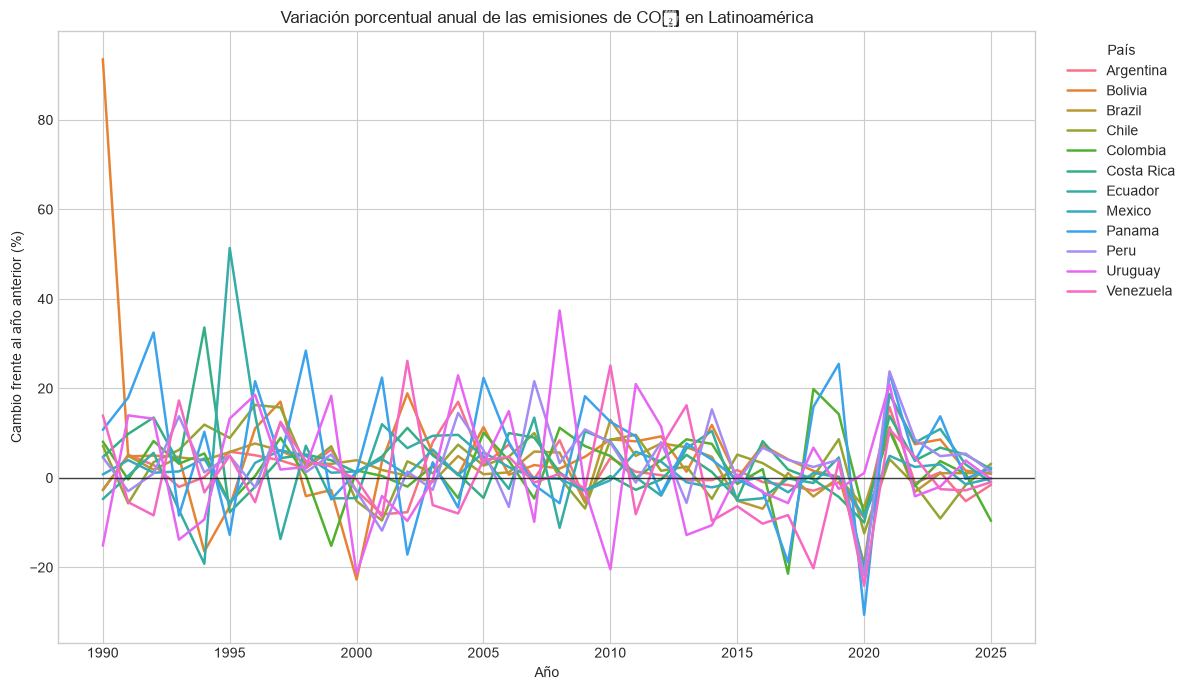

In [2]:
reciente = datos_latam[datos_latam["Year"] >= 1990]
plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(12, 7))
sns.lineplot(data=reciente, x="Year", y=columna, hue="Entity", linewidth=1.8)
plt.axhline(0, color="black", linewidth=1, alpha=0.7)
plt.title("Variación porcentual anual de las emisiones de CO₂ en Latinoamérica")
plt.xlabel("Año")
plt.ylabel("Cambio frente al año anterior (%)")
plt.legend(title="País", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Comparación en el último año disponible

C:\Users\Andre\AppData\Local\Temp\ipykernel_30928\1292968961.py:10: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()


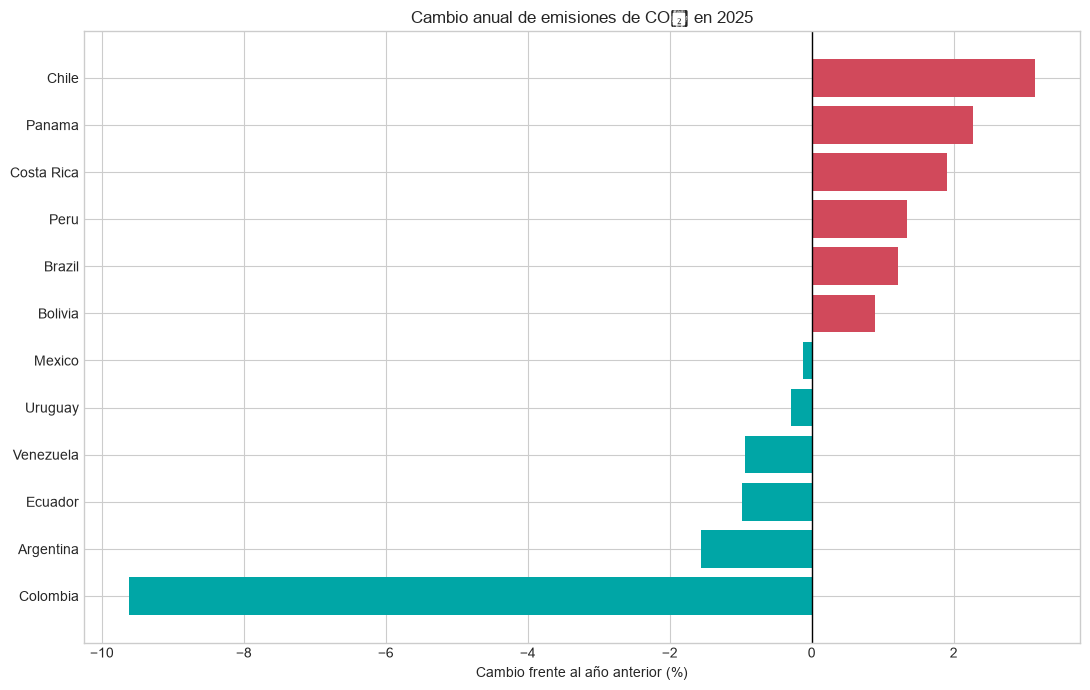

,Entity,Year,Year-on-year change in CO₂ emissions (%)
0,Colombia,2025,-9.616691
1,Argentina,2025,-1.557982
2,Ecuador,2025,-0.982934
3,Venezuela,2025,-0.940359
4,Uruguay,2025,-0.287855
5,Mexico,2025,-0.119996
6,Bolivia,2025,0.894666
7,Brazil,2025,1.210928
8,Peru,2025,1.348007
9,Costa Rica,2025,1.910818


In [3]:
ultimo_anio = int(datos_latam["Year"].max())
ultimos = datos_latam[datos_latam["Year"] == ultimo_anio].sort_values(columna)
plt.figure(figsize=(11, 7))
colores = ["#d1495b" if v >= 0 else "#00a6a6" for v in ultimos[columna]]
plt.barh(ultimos["Entity"], ultimos[columna], color=colores)
plt.axvline(0, color="black", linewidth=1)
plt.title(f"Cambio anual de emisiones de CO₂ en {ultimo_anio}")
plt.xlabel("Cambio frente al año anterior (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()
ultimos[["Entity", "Year", columna]].reset_index(drop=True)

## Caso de Colombia

C:\Users\Andre\AppData\Local\Temp\ipykernel_30928\4137234392.py:15: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Andre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


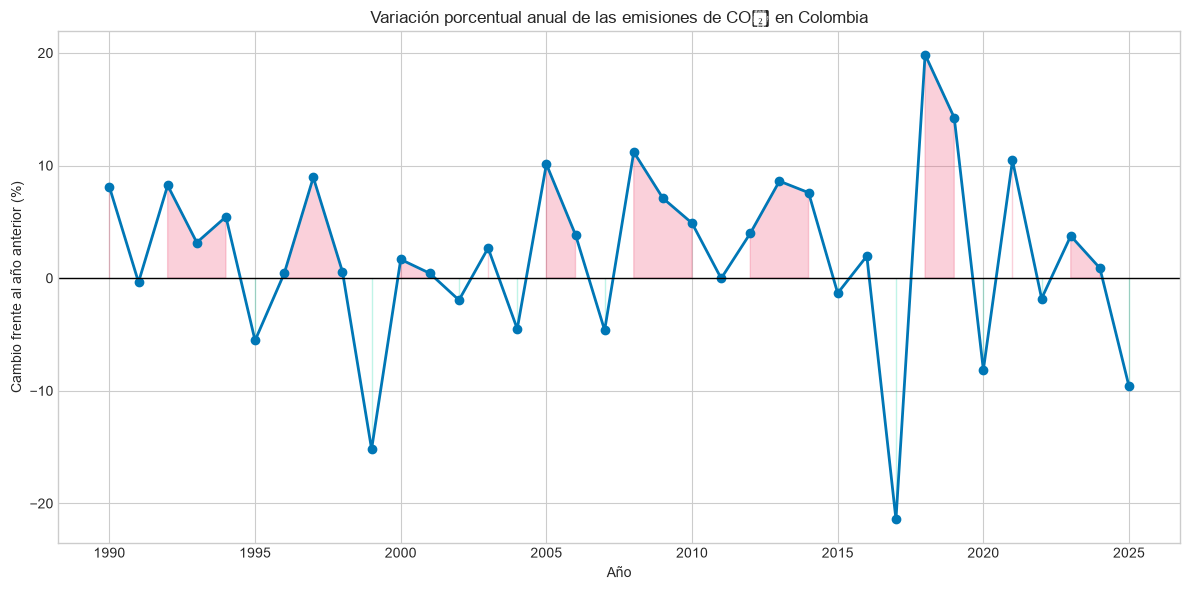

Colombia — 2025: -9.62%


In [4]:
colombia = datos_latam[
    (datos_latam["Entity"] == "Colombia") &
    (datos_latam["Year"] >= 1990)
]
plt.figure(figsize=(12, 6))
plt.plot(colombia["Year"], colombia[columna], marker="o", color="#0077b6", linewidth=2)
plt.axhline(0, color="black", linewidth=1)
plt.fill_between(colombia["Year"], colombia[columna], 0,
                 where=colombia[columna] >= 0, color="#ef476f", alpha=0.25)
plt.fill_between(colombia["Year"], colombia[columna], 0,
                 where=colombia[columna] < 0, color="#06d6a0", alpha=0.25)
plt.title("Variación porcentual anual de las emisiones de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("Cambio frente al año anterior (%)")
plt.tight_layout()
plt.show()

colombia_ultimo = colombia.sort_values("Year").iloc[-1]
print(f"{colombia_ultimo['Entity']} — {int(colombia_ultimo['Year'])}: "
      f"{colombia_ultimo[columna]:.2f}%")

## Resumen estadístico
La siguiente tabla presenta el promedio, el máximo y el mínimo de la variación anual desde 1990.

In [5]:
resumen = reciente.groupby("Entity")[columna].agg(["mean", "max", "min"])
resumen.columns = ["Promedio (%)", "Máximo (%)", "Mínimo (%)"]
resumen.round(2)

,Promedio (%),Máximo (%),Mínimo (%)
Entity,,,
Argentina,1.32,17.01,-8.95
Bolivia,5.69,93.57,-22.71
Brazil,2.33,12.95,-6.90
Chile,2.76,16.29,-12.39
Colombia,2.04,19.85,-21.42
Costa Rica,3.63,33.61,-9.97
Ecuador,3.10,51.37,-20.27
Mexico,1.20,6.33,-8.66
Panama,5.71,32.49,-30.61


## Conclusiones
- Los valores positivos representan años con mayor emisión que el año anterior.
- Los valores negativos representan reducciones interanuales.
- Deben interpretarse con cautela: cambios extraordinarios pueden estar asociados a recesiones, crisis energéticas, políticas públicas o eventos como la pandemia.
- El gráfico permite comparar tendencias, pero no representa el volumen absoluto de emisiones ni las emisiones per cápita.